# Daily & Session Range Analyzer

Historical daily and session range analysis for Candle Fetcher.

## Phase 1 ? Historical Range Analysis

Analyse daily highs, lows, point ranges and percentage ranges for Asia, London and New York.

In [4]:
from pathlib import Path
import sys

# Find the Candle Fetcher project root.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from src.range_analysis import calculate_range, calculate_daily_ranges, calculate_session_ranges

print('SUCCESS: Range Analyzer imports loaded!')

SUCCESS: Range Analyzer imports loaded!


In [5]:
# Step 2 ? Load historical candle data

DATA_FOLDER = PROJECT_ROOT / "data" / "processed" / "all_sessions"

available_files = sorted(DATA_FOLDER.glob("*.csv"))

print("Available historical datasets:")
for index, file in enumerate(available_files, start=1):
    print(f"{index}. {file.name}")

# Choose the dataset to analyse.
CSV_FILENAME = "2025_full_year.csv"

csv_path = DATA_FOLDER / CSV_FILENAME

if not csv_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {csv_path}")

df = pd.read_csv(csv_path, parse_dates=["datetime"])

print(f"\nLoaded: {CSV_FILENAME}")
print(f"Candles: {len(df):,}")
print(f"First candle: {df['datetime'].min()}")
print(f"Last candle: {df['datetime'].max()}")

display(df.head())


Available historical datasets:
1. 2023_full_year.csv
2. 2024_full_year.csv
3. 2025_full_year.csv
4. us100_cash_M1_all_sessions_2024_01_01_to_2024_12_31.csv
5. us100_cash_M1_all_sessions_2024_01_01_to_2025_01_01.csv

Loaded: 2025_full_year.csv
Candles: 348,793
First candle: 2025-01-02 01:05:00+00:00
Last candle: 2025-12-31 23:49:00+00:00


,datetime,open,high,low,close,tick_volume,spread,real_volume,session_name
0,2025-01-02 01:05:00+00:00,21100.15,21104.25,21088.65,21093.65,153,290,0,all_sessions
1,2025-01-02 01:06:00+00:00,21093.15,21093.75,21086.05,21091.35,119,290,0,all_sessions
2,2025-01-02 01:07:00+00:00,21091.65,21092.05,21086.15,21088.25,73,290,0,all_sessions
3,2025-01-02 01:08:00+00:00,21088.85,21097.25,21087.25,21096.05,70,290,0,all_sessions
4,2025-01-02 01:09:00+00:00,21098.05,21099.25,21091.75,21092.15,85,290,0,all_sessions


In [6]:

# Step 3 — Calculate historical daily ranges

daily_ranges = calculate_daily_ranges(
    df,
    timezone="UTC"
)

print("DAILY RANGE ANALYSIS — 2025")
print(f"Trading dates found: {len(daily_ranges)}")

display(daily_ranges.head(10))


DAILY RANGE ANALYSIS — 2025
Trading dates found: 258


,trading_date,high,low,candle_count,range_points,range_percent
0,2025-01-02,21273.95,20773.25,1365,500.7,2.4103
1,2025-01-03,21359.25,20936.85,1365,422.4,2.0175
2,2025-01-06,21703.45,21284.85,1365,418.6,1.9667
3,2025-01-07,21616.45,21094.05,1365,522.4,2.4765
4,2025-01-08,21262.95,20981.95,1365,281.0,1.3392
5,2025-01-09,21166.45,21036.95,925,129.5,0.6156
6,2025-01-10,21199.25,20706.15,1365,493.1,2.3814
7,2025-01-13,20868.45,20527.65,1365,340.8,1.6602
8,2025-01-14,20979.15,20611.75,1365,367.4,1.7825
9,2025-01-15,21288.55,20747.15,1365,541.4,2.6095


In [7]:
# Step 4 — Inspect historical daily candle coverage

coverage = (
    daily_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_day")
    .reset_index(name="number_of_days")
)

print("DAILY CANDLE COVERAGE — 2025")
display(coverage)

DAILY CANDLE COVERAGE — 2025


,candles_per_day,number_of_days
0,497,1
1,925,1
2,1135,7
3,1150,2
4,1346,1
5,1357,1
6,1364,2
7,1365,243


In [8]:
# Step 5 — Identify dates with reduced candle coverage

EXPECTED_CANDLES = 1365

reduced_coverage = daily_ranges[
    daily_ranges["candle_count"] < EXPECTED_CANDLES
].copy()

reduced_coverage["missing_vs_reference"] = (
    EXPECTED_CANDLES - reduced_coverage["candle_count"]
)

print("DATES WITH REDUCED CANDLE COVERAGE — 2025")
print(f"Number of dates: {len(reduced_coverage)}")

display(
    reduced_coverage[
        [
            "trading_date",
            "candle_count",
            "missing_vs_reference",
            "range_points",
            "range_percent"
        ]
    ]
)

DATES WITH REDUCED CANDLE COVERAGE — 2025
Number of dates: 15


,trading_date,candle_count,missing_vs_reference,range_points,range_percent
5,2025-01-09,925,440,129.50,0.6156
12,2025-01-20,1135,230,249.85,1.1689
32,2025-02-17,1135,230,88.70,0.4012
40,2025-02-27,1364,1,801.19,3.9033
48,2025-03-11,1357,8,542.50,2.8386
64,2025-04-02,1364,1,964.30,5.1014
101,2025-05-26,1135,230,314.50,1.5022
119,2025-06-19,1135,230,306.01,1.4285
129,2025-07-03,1150,215,283.50,1.2535
130,2025-07-04,1135,230,183.01,0.8069


In [9]:
# Step 6 — Classify daily candle coverage

EXPECTED_CANDLES = 1365

daily_ranges["coverage_status"] = daily_ranges[
    "candle_count"
].apply(
    lambda count: (
        "reference_coverage"
        if count == EXPECTED_CANDLES
        else "reduced_coverage"
    )
)

print("DAILY COVERAGE CLASSIFICATION — 2025")

coverage_summary = (
    daily_ranges["coverage_status"]
    .value_counts()
    .rename_axis("coverage_status")
    .reset_index(name="number_of_days")
)

display(coverage_summary)

DAILY COVERAGE CLASSIFICATION — 2025


,coverage_status,number_of_days
0,reference_coverage,243
1,reduced_coverage,15


In [10]:

# Step 7 — Historical daily range statistics

reference_days = daily_ranges[
    daily_ranges["coverage_status"] == "reference_coverage"
].copy()

ranges = reference_days["range_points"]

daily_statistics = pd.DataFrame({
    "Metric": [
        "Trading days",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(ranges),
        ranges.mean(),
        ranges.median(),
        ranges.min(),
        ranges.max(),
        ranges.quantile(0.10),
        ranges.quantile(0.25),
        ranges.quantile(0.75),
        ranges.quantile(0.90)
    ]
})

daily_statistics["Value"] = daily_statistics["Value"].round(2)

print("NAS100 — HISTORICAL DAILY RANGE STATISTICS (2025)")
print("Reference-coverage days only")

display(daily_statistics)


NAS100 — HISTORICAL DAILY RANGE STATISTICS (2025)
Reference-coverage days only


,Metric,Value
0,Trading days,243.00
1,Mean range,405.40
2,Median range (P50),346.29
3,Minimum range,100.10
4,Maximum range,2629.54
5,P10,187.82
6,P25,247.04
7,P75,493.10
8,P90,627.03


In [11]:
# Step 8 — Investigate the largest historical daily ranges

largest_days = (
    reference_days
    .sort_values("range_points", ascending=False)
    .head(10)
)

print("TOP 10 LARGEST DAILY RANGES — 2025")

display(
    largest_days[
        [
            "trading_date",
            "high",
            "low",
            "range_points",
            "range_percent",
            "candle_count"
        ]
    ]
)

TOP 10 LARGEST DAILY RANGES — 2025


,trading_date,high,low,range_points,range_percent,candle_count
69,2025-04-09,19234.59,16605.05,2629.54,15.8358,1365
67,2025-04-07,18216.99,16322.45,1894.54,11.6070,1365
70,2025-04-10,19234.89,17776.95,1457.94,8.2013,1365
68,2025-04-08,18218.05,16836.75,1381.30,8.2041,1365
66,2025-04-04,18555.05,17241.19,1313.86,7.6205,1365
229,2025-11-20,25223.15,23997.36,1225.79,5.1080,1365
200,2025-10-10,25199.75,24197.55,1002.20,4.1417,1365
17,2025-01-27,21574.45,20630.95,943.50,4.5732,1365
47,2025-03-10,20118.75,19237.85,880.90,4.5790,1365
79,2025-04-24,19291.86,18482.85,809.01,4.3771,1365


In [12]:

# Step 9 — Inspect the largest daily range

selected_date = "2025-04-09"

day_candles = df[
    df["datetime"].dt.strftime("%Y-%m-%d") == selected_date
].copy()

highest_candle = day_candles.loc[
    day_candles["high"].idxmax()
]

lowest_candle = day_candles.loc[
    day_candles["low"].idxmin()
]

print(f"DAILY RANGE INVESTIGATION — {selected_date}")
print(f"Total candles: {len(day_candles):,}")

print("\nDAILY HIGH")
print(f"Time (UTC): {highest_candle['datetime']}")
print(f"Price: {highest_candle['high']:,.2f}")

print("\nDAILY LOW")
print(f"Time (UTC): {lowest_candle['datetime']}")
print(f"Price: {lowest_candle['low']:,.2f}")

print("\nTOTAL RANGE")
print(
    f"{highest_candle['high'] - lowest_candle['low']:,.2f} points"
)


DAILY RANGE INVESTIGATION — 2025-04-09
Total candles: 1,365

DAILY HIGH
Time (UTC): 2025-04-09 22:55:00+00:00
Price: 19,234.59

DAILY LOW
Time (UTC): 2025-04-09 08:39:00+00:00
Price: 16,605.05

TOTAL RANGE
2,629.54 points


In [13]:

# Step 10 — Calculate historical New York session ranges

ny_ranges = calculate_session_ranges(
    df,
    session_name="new_york"
)

print("NEW YORK SESSION RANGES — 2025")
print(f"Trading dates found: {len(ny_ranges)}")

display(ny_ranges.head(10))


NEW YORK SESSION RANGES — 2025
Trading dates found: 258


,trading_date,session,high,low,candle_count,range_points,range_percent
0,2025-01-02,new_york,21273.95,20951.85,200,322.1,1.5373
1,2025-01-03,new_york,21238.95,21008.45,200,230.5,1.0972
2,2025-01-06,new_york,21693.85,21451.35,200,242.5,1.1305
3,2025-01-07,new_york,21616.45,21336.85,200,279.6,1.3104
4,2025-01-08,new_york,21220.85,21036.25,200,184.6,0.8775
5,2025-01-09,new_york,21155.75,21086.75,140,69.0,0.3272
6,2025-01-10,new_york,21151.95,20706.15,200,445.8,2.1530
7,2025-01-13,new_york,20691.35,20539.25,200,152.1,0.7405
8,2025-01-14,new_york,20971.75,20778.15,200,193.6,0.9317
9,2025-01-15,new_york,21245.75,20816.65,200,429.1,2.0613


In [14]:
# Step 11 — Check New York session candle coverage

ny_coverage = (
    ny_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

print("NEW YORK SESSION COVERAGE — 2025")
display(ny_coverage)

print(f"\nTotal sessions: {len(ny_ranges)}")
print(
    "Sessions with exactly 200 candles:",
    (ny_ranges["candle_count"] == 200).sum()
)

NEW YORK SESSION COVERAGE — 2025


,candles_per_session,number_of_sessions
0,100,1
1,140,1
2,181,1
3,196,1
4,200,254



Total sessions: 258
Sessions with exactly 200 candles: 254


In [15]:

# Step 12 — New York historical session range statistics

ny_reference = ny_ranges[
    ny_ranges["candle_count"] == 200
].copy()

ny_points = ny_reference["range_points"]

ny_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(ny_points),
        ny_points.mean(),
        ny_points.median(),
        ny_points.min(),
        ny_points.max(),
        ny_points.quantile(0.10),
        ny_points.quantile(0.25),
        ny_points.quantile(0.75),
        ny_points.quantile(0.90)
    ]
})

ny_statistics["Value"] = ny_statistics["Value"].round(2)

print("NAS100 — NEW YORK SESSION RANGE STATISTICS (2025)")
print("Session: 09:10–12:30 America/New_York")
print("Sessions with 200 candles only")

display(ny_statistics)


NAS100 — NEW YORK SESSION RANGE STATISTICS (2025)
Session: 09:10–12:30 America/New_York
Sessions with 200 candles only


,Metric,Value
0,Sessions analysed,254.00
1,Mean range,161.60
2,Median range (P50),127.30
3,Minimum range,30.50
4,Maximum range,654.10
5,P10,54.64
6,P25,77.93
7,P75,218.02
8,P90,324.76


In [16]:

# Step 13 — Calculate historical London session ranges

london_ranges = calculate_session_ranges(
    df,
    session_name="london"
)

print("LONDON SESSION RANGES — 2025")
print("Session: 08:00–11:00 Europe/London")
print(f"Trading dates found: {len(london_ranges)}")

display(london_ranges.head(10))

print("\nLONDON SESSION CANDLE COVERAGE")

london_coverage = (
    london_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

display(london_coverage)



LONDON SESSION RANGES — 2025
Session: 08:00–11:00 Europe/London
Trading dates found: 258


,trading_date,session,high,low,candle_count,range_points,range_percent
0,2025-01-02,london,21207.85,21102.35,180,105.5,0.4999
1,2025-01-03,london,21074.75,21010.75,180,64.0,0.3046
2,2025-01-06,london,21429.85,21335.95,180,93.9,0.4401
3,2025-01-07,london,21575.85,21494.65,180,81.2,0.3778
4,2025-01-08,london,21249.65,21175.75,180,73.9,0.3490
5,2025-01-09,london,21147.55,21036.95,180,110.6,0.5257
6,2025-01-10,london,21128.75,21061.45,180,67.3,0.3195
7,2025-01-13,london,20761.15,20629.85,180,131.3,0.6365
8,2025-01-14,london,20979.15,20857.25,180,121.9,0.5844
9,2025-01-15,london,20797.25,20747.15,180,50.1,0.2415



LONDON SESSION CANDLE COVERAGE


,candles_per_session,number_of_sessions
0,2,1
1,180,257


In [17]:

# Step 14 — London historical session range statistics

london_reference = london_ranges[
    london_ranges["candle_count"] == 180
].copy()

london_points = london_reference["range_points"]

london_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(london_points),
        london_points.mean(),
        london_points.median(),
        london_points.min(),
        london_points.max(),
        london_points.quantile(0.10),
        london_points.quantile(0.25),
        london_points.quantile(0.75),
        london_points.quantile(0.90)
    ]
})

london_statistics["Value"] = london_statistics["Value"].round(2)

print("NAS100 — LONDON SESSION RANGE STATISTICS (2025)")
print("Session: 08:00–11:00 Europe/London")
print("Sessions with 180 candles only")

display(london_statistics)


NAS100 — LONDON SESSION RANGE STATISTICS (2025)
Session: 08:00–11:00 Europe/London
Sessions with 180 candles only


,Metric,Value
0,Sessions analysed,257.00
1,Mean range,80.53
2,Median range (P50),67.30
3,Minimum range,14.80
4,Maximum range,403.50
5,P10,36.66
6,P25,47.10
7,P75,97.30
8,P90,132.54


In [18]:

# Step 15 — Calculate historical Asia session ranges

asia_ranges = calculate_session_ranges(
    df,
    session_name="asia"
)

print("ASIA SESSION RANGES — 2025")
print("Session: 09:00–12:00 Asia/Tokyo")
print(f"Trading dates found: {len(asia_ranges)}")

display(asia_ranges.head(10))

print("\nASIA SESSION CANDLE COVERAGE")

asia_coverage = (
    asia_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

display(asia_coverage)


ASIA SESSION RANGES — 2025
Session: 09:00–12:00 Asia/Tokyo
Trading dates found: 258


,trading_date,session,high,low,candle_count,range_points,range_percent
0,2025-01-02,asia,21104.25,20905.65,115,198.6,0.9500
1,2025-01-03,asia,21031.95,20936.85,115,95.1,0.4542
2,2025-01-06,asia,21343.05,21284.85,115,58.2,0.2734
3,2025-01-07,asia,21603.25,21562.55,115,40.7,0.1888
4,2025-01-08,asia,21228.95,21159.45,115,69.5,0.3285
5,2025-01-09,asia,21164.15,21088.85,115,75.3,0.3571
6,2025-01-10,asia,21120.85,21003.55,115,117.3,0.5585
7,2025-01-13,asia,20868.45,20775.05,115,93.4,0.4496
8,2025-01-14,asia,20923.95,20856.45,115,67.5,0.3236
9,2025-01-15,asia,20799.25,20774.85,115,24.4,0.1174



ASIA SESSION CANDLE COVERAGE


,candles_per_session,number_of_sessions
0,114,1
1,115,257


In [19]:

# Step 16 — Inspect Asia session candle timestamps

selected_date = "2025-01-02"

asia_candles = df[
    df["datetime"].dt.tz_convert("Asia/Tokyo")
    .dt.strftime("%Y-%m-%d") == selected_date
].copy()

asia_local = asia_candles[
    "datetime"
].dt.tz_convert("Asia/Tokyo")

asia_candles = asia_candles[
    (asia_local.dt.hour >= 9) &
    (asia_local.dt.hour < 12)
].copy()

print(f"ASIA SESSION TIMESTAMP CHECK — {selected_date}")
print(f"Total candles: {len(asia_candles)}")

print("\nFirst 10 timestamps:")
print(
    asia_candles["datetime"]
    .dt.tz_convert("Asia/Tokyo")
    .head(10)
    .to_string(index=False)
)

print("\nLast 10 timestamps:")
print(
    asia_candles["datetime"]
    .dt.tz_convert("Asia/Tokyo")
    .tail(10)
    .to_string(index=False)
)

print("\nGaps larger than one minute:")

time_gaps = asia_candles[
    "datetime"
].diff()

print(time_gaps[time_gaps > pd.Timedelta(minutes=1)])


ASIA SESSION TIMESTAMP CHECK — 2025-01-02
Total candles: 115

First 10 timestamps:
2025-01-02 10:05:00+09:00
2025-01-02 10:06:00+09:00
2025-01-02 10:07:00+09:00
2025-01-02 10:08:00+09:00
2025-01-02 10:09:00+09:00
2025-01-02 10:10:00+09:00
2025-01-02 10:11:00+09:00
2025-01-02 10:12:00+09:00
2025-01-02 10:13:00+09:00
2025-01-02 10:14:00+09:00

Last 10 timestamps:
2025-01-02 11:50:00+09:00
2025-01-02 11:51:00+09:00
2025-01-02 11:52:00+09:00
2025-01-02 11:53:00+09:00
2025-01-02 11:54:00+09:00
2025-01-02 11:55:00+09:00
2025-01-02 11:56:00+09:00
2025-01-02 11:57:00+09:00
2025-01-02 11:58:00+09:00
2025-01-02 11:59:00+09:00

Gaps larger than one minute:
Series([], Name: datetime, dtype: timedelta64[us])


In [20]:

# Step 17 — Asia historical session range statistics

asia_reference = asia_ranges[
    asia_ranges["candle_count"] == 115
].copy()

asia_points = asia_reference["range_points"]

asia_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(asia_points),
        asia_points.mean(),
        asia_points.median(),
        asia_points.min(),
        asia_points.max(),
        asia_points.quantile(0.10),
        asia_points.quantile(0.25),
        asia_points.quantile(0.75),
        asia_points.quantile(0.90)
    ]
})

asia_statistics["Value"] = asia_statistics["Value"].round(2)

print("NAS100 — ASIA SESSION RANGE STATISTICS (2025)")
print("Configured: 09:00–12:00 Asia/Tokyo")
print("Observed reference coverage: 10:05–12:00")
print("Sessions with 115 candles only")

display(asia_statistics)


NAS100 — ASIA SESSION RANGE STATISTICS (2025)
Configured: 09:00–12:00 Asia/Tokyo
Observed reference coverage: 10:05–12:00
Sessions with 115 candles only


,Metric,Value
0,Sessions analysed,257.00
1,Mean range,74.03
2,Median range (P50),60.69
3,Minimum range,13.89
4,Maximum range,382.00
5,P10,27.40
6,P25,36.39
7,P75,89.49
8,P90,134.09


In [21]:

# Step 18 — Compare daily and session range statistics

datasets = {
    "Full Day": reference_days["range_points"],
    "Asia": asia_reference["range_points"],
    "London": london_reference["range_points"],
    "New York": ny_reference["range_points"],
}

comparison_rows = []

for name, ranges in datasets.items():
    comparison_rows.append({
        "Period": name,
        "Observations": len(ranges),
        "Mean": ranges.mean(),
        "Median": ranges.median(),
        "P10": ranges.quantile(0.10),
        "P25": ranges.quantile(0.25),
        "P75": ranges.quantile(0.75),
        "P90": ranges.quantile(0.90),
        "Maximum": ranges.max(),
    })

range_comparison = pd.DataFrame(comparison_rows)

numeric_columns = range_comparison.select_dtypes(
    include="number"
).columns.drop("Observations")

range_comparison[numeric_columns] = (
    range_comparison[numeric_columns].round(2)
)

print("NAS100 — HISTORICAL RANGE COMPARISON (2025)")
print("All ranges measured in index points")

display(range_comparison)


NAS100 — HISTORICAL RANGE COMPARISON (2025)
All ranges measured in index points


,Period,Observations,Mean,Median,P10,P25,P75,P90,Maximum
0,Full Day,243,405.40,346.29,187.82,247.04,493.10,627.03,2629.54
1,Asia,257,74.03,60.69,27.40,36.39,89.49,134.09,382.00
2,London,257,80.53,67.30,36.66,47.10,97.30,132.54,403.50
3,New York,254,161.60,127.30,54.64,77.93,218.02,324.76,654.10


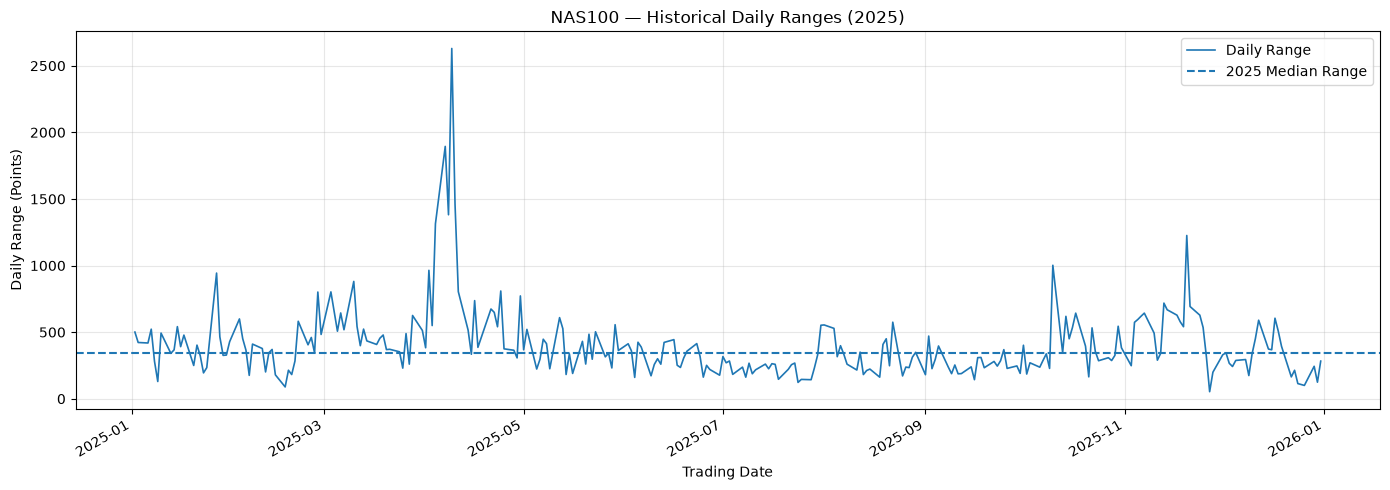

In [22]:

# Step 19 — Visualise historical daily ranges

import matplotlib.pyplot as plt

chart_data = daily_ranges.copy()
chart_data["trading_date"] = pd.to_datetime(
    chart_data["trading_date"]
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    chart_data["trading_date"],
    chart_data["range_points"],
    linewidth=1.2,
    label="Daily Range"
)

ax.axhline(
    y=reference_days["range_points"].median(),
    linestyle="--",
    linewidth=1.5,
    label="2025 Median Range"
)

ax.set_title("NAS100 — Historical Daily Ranges (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Daily Range (Points)")

ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()
